# Week 7: Comparative Error Analysis and Investigation of Method Limitations

## ECE501 — Digital Image Processing
### Project: Vehicle Orientation Estimation Using Conventional Image Processing

### Objective

The objective of Week 7 is to investigate the limitations of the conventional image-processing methods used for vehicle orientation estimation.

The analysis uses the same 100 vehicle observations selected in the earlier weeks. No additional vehicles are introduced, and the existing estimation algorithms are not modified.

The methods considered are:

1. Principal Component Analysis (PCA)
2. Original Hough Transform
3. Modified Hough Transform
4. Contour-Based Orientation Estimation

The study compares the angular errors produced by these methods and investigates whether they encounter difficulties on the same vehicle classes or individual vehicle images.

Special attention is given to cases where multiple methods produce large errors and where Modified Hough performs worse than the original implementation.

The analysis also includes visual inspection of vehicle crops, edge maps, and detected Hough lines to investigate possible causes of inaccurate orientation estimation.

### Expected Outcomes

- Overall performance comparison of the existing methods.
- Vehicle-class-wise angular error analysis.
- Identification of common high-error observations.
- Comparison of Original and Modified Hough Transform.
- Visual investigation of difficult vehicle images.
- Documentation of method-specific and shared limitations.

The project continues to estimate vehicle orientation in the 0°–90° range. Front–rear identification is not included in Week 7.

In [19]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from IPython.display import display

BASE = Path('/content/drive/MyDrive/ECE501_DRASHTI')

W3 = BASE / 'Week3_Results'
W6 = BASE / 'Week6_Results'

OUT = BASE / 'Week7_Results'

TABLE = OUT / 'tables'
FIG = OUT / 'graphs'
VIS = OUT / 'visualizations'

for folder in [TABLE, FIG, VIS]:
    folder.mkdir(parents=True, exist_ok=True)

W3_CSV = W3 / 'week3_100_image_error_table.csv'
CROPS = W6 / 'vehicle_crops'

source = pd.read_csv(W3_CSV)

assert len(source) == 100, "Expected exactly 100 observations"
assert source['Vehicle_ID'].is_unique, "Duplicate vehicle IDs found"

print("Total vehicles:", len(source))
print("Output folder:", OUT)

display(source.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total vehicles: 100
Output folder: /content/drive/MyDrive/ECE501_DRASHTI/Week7_Results


,Vehicle_ID,Image_ID,Vehicle_Number,Class_ID,Vehicle_Class,Difficulty,Ground_Truth_Heading_deg,Ground_Truth_Orientation_deg,PCA_Estimated_Orientation_deg,PCA_Angular_Error_deg,Hough_Estimated_Orientation_deg,Hough_Angular_Error_deg,Contour_Estimated_Orientation_deg,Contour_Angular_Error_deg
0,KNyT_zacV_LpYg_vehicle_1,KNyT_zacV_LpYg,1,5,MotorCycle,0,283.20,76.80,72.51,4.29,82.44,5.64,86.31,9.51
1,IwEd_XCYw_iwrB_vehicle_1,IwEd_XCYw_iwrB,1,0,Auto3WCargo,0,214.74,34.74,5.61,29.13,54.72,19.98,0.00,34.74
2,C2g2_vYbb_ihYH_vehicle_1,C2g2_vYbb_ihYH,1,7,SUV,0,239.58,59.58,50.14,9.44,69.57,9.99,52.43,7.15
3,gqbe_NCQI_MTLw_vehicle_1,gqbe_NCQI_MTLw,1,7,SUV,0,171.34,8.66,0.84,7.82,10.04,1.38,0.00,8.66
4,boDi_WlMN_s88Y_vehicle_1,boDi_WlMN_s88Y,1,9,Tanker,0,97.00,83.00,83.19,0.19,86.27,3.27,90.00,7.00


## 1. Reusing the Original 100 Vehicle Observations

To maintain consistency with the previous experiments, Week 7 uses exactly the same 100 vehicle observations.

The vehicle identifiers, vehicle classes, ground-truth orientations, and previously calculated predictions are obtained from the Week 3 results.

The vehicle crops reconstructed during Week 6 are reused for visual investigation and Hough Transform evaluation.

No new vehicles are added, and no existing vehicle identifiers are removed.

If a crop is unavailable, the corresponding vehicle remains in the analysis table. The missing crop is recorded rather than being replaced with a different observation.

This ensures that the comparison remains based on the original evaluation sample.

In [20]:
manifest_file = W6 / 'tables' / '01_vehicle_crop_manifest.csv'

if manifest_file.exists():
    manifest = pd.read_csv(manifest_file)
else:
    manifest = pd.DataFrame(
        columns=['Vehicle_ID', 'Crop_Path']
    )

if 'Crop_Path' not in manifest.columns:
    manifest['Crop_Path'] = np.nan

manifest = manifest.drop_duplicates('Vehicle_ID')

df = source.merge(
    manifest[['Vehicle_ID', 'Crop_Path']],
    on='Vehicle_ID',
    how='left',
    validate='one_to_one'
)

def locate_crop(row):

    candidates = [
        row.Crop_Path if isinstance(row.Crop_Path, str) else None,
        str(CROPS / (row.Vehicle_ID + '.jpg'))
    ]

    for path in candidates:

        if path is None:
            continue

        if Path(path).exists():

            image = cv2.imread(str(path))

            if image is not None:
                return str(path)

    return None


df['Crop_Path'] = [
    locate_crop(row)
    for row in df.itertuples(index=False)
]

df['Crop_Available'] = df['Crop_Path'].notna()

assert len(df) == 100

assert set(df['Vehicle_ID']) == set(source['Vehicle_ID'])

print("Total observations:", len(df))
print("Available crops:", df['Crop_Available'].sum())
print("Unavailable crops:", (~df['Crop_Available']).sum())

display(
    df.loc[
        ~df['Crop_Available'],
        ['Vehicle_ID', 'Vehicle_Class']
    ]
)

Total observations: 100
Available crops: 100
Unavailable crops: 0


,Vehicle_ID,Vehicle_Class


## 2. Loading the Original Orientation Estimation Results

The original PCA, Hough Transform, and Contour-Based orientation predictions were calculated during Week 3.

Rather than implementing these methods again, their saved predictions are reused directly.

This preserves the original experimental methodology and prevents differences caused by changing preprocessing steps or algorithm parameters.

For each method, angular error is calculated as:

Angular Error = |Ground-Truth Orientation − Estimated Orientation|

Both orientations are represented in the 0°–90° range.

A missing prediction is treated as an unavailable result and is not assigned an arbitrary angular error.

In [21]:
METHOD_COLS = {
    'PCA': 'PCA_Estimated_Orientation_deg',

    'Original_Hough_Week3':
        'Hough_Estimated_Orientation_deg',

    'Contour':
        'Contour_Estimated_Orientation_deg'
}

GT = 'Ground_Truth_Orientation_deg'

df[GT] = pd.to_numeric(
    df[GT],
    errors='coerce'
)

for method, column in METHOD_COLS.items():

    df[column] = pd.to_numeric(
        df[column],
        errors='coerce'
    )

    df[method + '_error'] = abs(
        df[GT] - df[column]
    )

print("Historical methods loaded successfully.")

display(
    df[
        [
            'Vehicle_ID',
            'Vehicle_Class',
            GT,
            'PCA_error',
            'Original_Hough_Week3_error',
            'Contour_error'
        ]
    ].head()
)

Historical methods loaded successfully.


,Vehicle_ID,Vehicle_Class,Ground_Truth_Orientation_deg,PCA_error,Original_Hough_Week3_error,Contour_error
0,KNyT_zacV_LpYg_vehicle_1,MotorCycle,76.80,4.29,5.64,9.51
1,IwEd_XCYw_iwrB_vehicle_1,Auto3WCargo,34.74,29.13,19.98,34.74
2,C2g2_vYbb_ihYH_vehicle_1,SUV,59.58,9.44,9.99,7.15
3,gqbe_NCQI_MTLw_vehicle_1,SUV,8.66,7.82,1.38,8.66
4,boDi_WlMN_s88Y_vehicle_1,Tanker,83.00,0.19,3.27,7.00


## 3. Original and Modified Hough Transform

During Week 6, the Hough Transform was investigated because it produced comparatively large angular errors on certain vehicle images.

The existing preprocessing pipeline includes:

1. Grayscale conversion.
2. CLAHE contrast enhancement.
3. Gaussian smoothing.
4. Canny edge detection.
5. Morphological closing.

The Hough Transform detects line segments in the resulting edge image.

The original Week 6 baseline estimates orientation using the detected line directions and their lengths.

The Modified Hough Transform introduces two previously implemented adjustments:

- Short-line filtering: Removes detected line segments shorter than a specified fraction of the crop diagonal.
- Dominant orientation grouping: Selects the group of line segments with the greatest combined length.

The selected line directions are combined using a length-weighted axial mean.

In Week 7, these implementations are reused without introducing additional image-processing techniques.

The original Week 3 Hough results and the Week 6 baseline are retained as separate comparisons because their implementations are not necessarily identical.

In [22]:
def preprocess_vehicle(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    blurred = cv2.GaussianBlur(
        enhanced,
        (5, 5),
        0
    )

    edges = cv2.Canny(
        blurred,
        50,
        150
    )

    kernel = np.ones(
        (3, 3),
        np.uint8
    )

    edges = cv2.morphologyEx(
        edges,
        cv2.MORPH_CLOSE,
        kernel
    )

    return edges


def detect_hough_lines(
    edges,
    threshold=30,
    min_line_length=20,
    max_line_gap=10
):

    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 180,
        threshold=threshold,
        minLineLength=min_line_length,
        maxLineGap=max_line_gap
    )

    if lines is None:

        return np.empty(
            (0, 4),
            dtype=np.int32
        )

    return lines.reshape(-1, 4)


def get_line_properties(lines):

    if len(lines) == 0:
        return np.array([]), np.array([])

    dx = lines[:, 2] - lines[:, 0]
    dy = lines[:, 3] - lines[:, 1]

    lengths = np.hypot(dx, dy)

    angles = (
        np.degrees(
            np.arctan2(dy, dx)
        ) % 180
    )

    return angles, lengths


def axial_mean(angles, weights):

    if len(angles) == 0:
        return np.nan

    doubled_angles = np.deg2rad(
        2 * angles
    )

    x = np.sum(
        weights * np.cos(doubled_angles)
    )

    y = np.sum(
        weights * np.sin(doubled_angles)
    )

    if np.hypot(x, y) < 1e-10:
        return np.nan

    return (
        np.degrees(
            np.arctan2(y, x)
        ) / 2
    ) % 180


def fold_orientation(axis):

    if not np.isfinite(axis):
        return np.nan

    axis = axis % 180

    return min(
        axis,
        180 - axis
    )

In [23]:
def baseline_hough(image):

    edges = preprocess_vehicle(image)

    lines = detect_hough_lines(
        edges
    )

    angles, lengths = get_line_properties(
        lines
    )

    axis = axial_mean(
        angles,
        lengths
    )

    orientation = fold_orientation(
        axis
    )

    return (
        orientation,
        axis,
        lines,
        edges
    )

In [24]:
def modified_hough(
    image,
    threshold=30,
    min_line_length=20,
    max_line_gap=10,
    min_relative_length=0.08,
    bin_width=15
):

    edges = preprocess_vehicle(image)

    lines = detect_hough_lines(
        edges,
        threshold=threshold,
        min_line_length=min_line_length,
        max_line_gap=max_line_gap
    )

    angles, lengths = get_line_properties(
        lines
    )

    if len(lines) == 0:

        return (
            np.nan,
            np.nan,
            lines,
            lines,
            edges
        )

    height, width = image.shape[:2]

    min_length = (
        min_relative_length
        * np.hypot(height, width)
    )

    valid = lengths >= min_length

    filtered_lines = lines[valid]
    filtered_angles = angles[valid]
    filtered_lengths = lengths[valid]

    if len(filtered_lines) == 0:

        return (
            np.nan,
            np.nan,
            lines,
            filtered_lines,
            edges
        )

    centers = np.arange(
        0,
        180,
        bin_width
    )

    scores = []

    for center in centers:

        distance = np.abs(
            (
                filtered_angles
                - center
                + 90
            ) % 180 - 90
        )

        selected = (
            distance <= bin_width / 2
        )

        scores.append(
            filtered_lengths[selected].sum()
        )

    best_center = centers[
        np.argmax(scores)
    ]

    distance = np.abs(
        (
            filtered_angles
            - best_center
            + 90
        ) % 180 - 90
    )

    selected = (
        distance <= bin_width / 2
    )

    selected_lines = filtered_lines[
        selected
    ]

    axis = axial_mean(
        filtered_angles[selected],
        filtered_lengths[selected]
    )

    orientation = fold_orientation(
        axis
    )

    return (
        orientation,
        axis,
        lines,
        selected_lines,
        edges
    )

## 4. Reusing the Selected Modified Hough Parameters

Week 6 evaluated multiple parameter combinations to investigate the effect of Hough line-detection and filtering settings.

For Week 7, the previously selected parameter configuration is reused.

No additional parameter tuning is performed.

This ensures that any observed differences arise from the existing algorithms and vehicle characteristics rather than newly introduced parameter changes.

The selected configuration is loaded from the Week 6 parameter-tuning results.

In [25]:
tuning_file = (
    W6 / 'tables' / '04_parameter_tuning.csv'
)

assert tuning_file.exists(), (
    f"Cannot find parameter table: {tuning_file}"
)

tune = pd.read_csv(tuning_file)

tune = tune.sort_values(
    'Selection_Score'
)

best = tune.iloc[0]

BEST_PARAMS = {
    'threshold': int(best.Threshold),

    'min_line_length': int(best.Min_Line_Length),

    'max_line_gap': int(best.Max_Line_Gap),

    'min_relative_length':
        float(best.Min_Relative_Length),

    'bin_width': int(best.Bin_Width)
}

print("Selected Week 6 parameters:")

for key, value in BEST_PARAMS.items():
    print(key, ":", value)

Selected Week 6 parameters:
threshold : 30
min_line_length : 15
max_line_gap : 5
min_relative_length : 0.05
bin_width : 20


## 5. Evaluation of Original and Modified Hough Transform

The Week 6 baseline and Modified Hough Transform are evaluated using the available vehicle crops from the original 100 observations.

For each vehicle, the following information is recorded:

- Vehicle identifier.
- Ground-truth orientation.
- Baseline Hough estimated orientation.
- Modified Hough estimated orientation.
- Number of detected line segments.
- Number of selected line segments.
- Angular error for each method.

The evaluation preserves all 100 vehicle identifiers.

If an image crop cannot be loaded, its prediction is recorded as unavailable instead of replacing the observation.

The resulting table is saved for further comparison with the historical PCA, Original Hough, and Contour results.

In [26]:
rows = []

for row in df.itertuples(index=False):

    result = {
        'Vehicle_ID': row.Vehicle_ID,
        'Week6_Baseline': np.nan,
        'Modified_Hough': np.nan,
        'Detected_Lines': np.nan,
        'Selected_Lines': np.nan
    }

    if row.Crop_Available:

        image = cv2.imread(row.Crop_Path)

        if image is not None:

            baseline, _, _, _ = baseline_hough(image)

            modified, _, all_lines, selected_lines, _ = (
                modified_hough(
                    image,
                    **BEST_PARAMS
                )
            )

            result.update({
                'Week6_Baseline': baseline,
                'Modified_Hough': modified,
                'Detected_Lines': len(all_lines),
                'Selected_Lines': len(selected_lines)
            })

    rows.append(result)


hough_results = pd.DataFrame(rows)

df = df.merge(
    hough_results,
    on='Vehicle_ID',
    validate='one_to_one'
)

for method in ['Week6_Baseline', 'Modified_Hough']:

    df[method + '_error'] = abs(
        df[GT] - df[method]
    )

assert len(df) == 100
assert df['Vehicle_ID'].is_unique

ERRORS = [
    'PCA_error',
    'Original_Hough_Week3_error',
    'Contour_error',
    'Week6_Baseline_error',
    'Modified_Hough_error'
]

df.to_csv(
    TABLE / '01_all_100_comparison.csv',
    index=False
)

print("Evaluation completed.")

display(
    df[
        ['Vehicle_ID', 'Vehicle_Class', 'Crop_Available']
        + ERRORS
    ].head()
)

Evaluation completed.


,Vehicle_ID,Vehicle_Class,Crop_Available,PCA_error,Original_Hough_Week3_error,Contour_error,Week6_Baseline_error,Modified_Hough_error
0,KNyT_zacV_LpYg_vehicle_1,MotorCycle,True,4.29,5.64,9.51,0.486686,16.886478
1,IwEd_XCYw_iwrB_vehicle_1,Auto3WCargo,True,29.13,19.98,34.74,21.199293,3.530037
2,C2g2_vYbb_ihYH_vehicle_1,SUV,True,9.44,9.99,7.15,7.392224,5.554543
3,gqbe_NCQI_MTLw_vehicle_1,SUV,True,7.82,1.38,8.66,78.959036,1.353955
4,boDi_WlMN_s88Y_vehicle_1,Tanker,True,0.19,3.27,7.00,3.998429,1.288833


## 6. Overall Performance Comparison

The first stage of the analysis compares the overall angular errors of the existing orientation-estimation methods.

The following performance measures are calculated:

1. Number of valid predictions.
2. Number of unavailable predictions.
3. Mean Angular Error (MAE).
4. Median Angular Error.
5. Number of predictions with angular error greater than or equal to 30°.

Mean Angular Error is calculated as:

MAE = (Sum of Absolute Angular Errors) / (Number of Valid Predictions)

The mean error indicates the overall estimation accuracy, while the median provides information about the typical error.

The number of high-error predictions is also considered because a method may produce accurate results for most vehicles but fail significantly on a small number of observations.

Unavailable predictions are counted separately to avoid misleading comparisons.

In [27]:
summary = []

for method in ERRORS:

    errors = df[method]

    summary.append({
        'Method': method,
        'Total_Vehicles': len(df),
        'Valid_Predictions': errors.notna().sum(),
        'Unavailable_Predictions': errors.isna().sum(),
        'Mean_Error': errors.mean(),
        'Median_Error': errors.median(),
        'Maximum_Error': errors.max(),
        'Standard_Deviation': errors.std(),
        'High_Error_Count_30deg': (errors >= 30).sum()
    })

overall = pd.DataFrame(summary)

overall.to_csv(
    TABLE / '02_overall_comparison.csv',
    index=False
)

display(overall.round(2))

,Method,Total_Vehicles,Valid_Predictions,Unavailable_Predictions,Mean_Error,Median_Error,Maximum_Error,Standard_Deviation,High_Error_Count_30deg
0,PCA_error,100,100,0,10.74,4.85,81.71,16.11,8
1,Original_Hough_Week3_error,100,98,2,12.46,4.18,82.39,20.44,11
2,Contour_error,100,100,0,10.97,5.72,89.00,16.44,12
3,Week6_Baseline_error,100,100,0,7.85,3.98,82.68,14.54,5
4,Modified_Hough_error,100,100,0,5.35,2.02,84.94,11.12,3


## 7. Vehicle-Class-Wise Error Analysis

Different vehicle classes have different geometric structures, sizes, and visual characteristics.

These differences may affect the performance of conventional orientation-estimation methods.

In this section, the angular errors are grouped according to vehicle class.

For each method and vehicle class, the following are calculated:

- Number of vehicle observations.
- Number of valid predictions.
- Mean angular error.
- Median angular error.
- Maximum angular error.
- Number of high-error predictions.

The objective is to determine whether particular vehicle classes consistently produce large errors across PCA, Original Hough, Modified Hough, and Contour.

However, class-wise conclusions must be interpreted carefully because the original 100 observations are not equally distributed across vehicle classes.

A high mean error based on only one or two vehicles does not establish that the method performs poorly for the entire class.

In [28]:
class_results = []

for vehicle_class, group in df.groupby('Vehicle_Class'):

    for method in ERRORS:

        errors = group[method]

        class_results.append({
            'Vehicle_Class': vehicle_class,
            'Method': method,
            'Sample_Count': len(group),
            'Valid_Predictions': errors.notna().sum(),
            'Mean_Error': errors.mean(),
            'Median_Error': errors.median(),
            'Maximum_Error': errors.max(),
            'High_Error_Count_30deg': (errors >= 30).sum()
        })

classwise = pd.DataFrame(class_results)

classwise.to_csv(
    TABLE / '03_classwise_comparison.csv',
    index=False
)

display(
    classwise.sort_values(
        'Mean_Error',
        ascending=False
    ).round(2)
)

,Vehicle_Class,Method,Sample_Count,Valid_Predictions,Mean_Error,Median_Error,Maximum_Error,High_Error_Count_30deg
16,Container,Original_Hough_Week3_error,3,2,49.13,49.13,77.16,1
15,Container,PCA_error,3,3,40.12,42.07,43.61,3
1,Auto3WCargo,Original_Hough_Week3_error,3,3,38.58,19.98,81.49,1
46,Trailer,Original_Hough_Week3_error,3,3,32.87,8.91,82.39,1
47,Trailer,Contour_error,3,3,30.21,0.82,89.00,1
45,Trailer,PCA_error,3,3,28.97,4.07,81.71,1
17,Container,Contour_error,3,3,27.49,34.10,42.36,2
10,Bus,PCA_error,2,2,27.32,27.32,52.71,1
12,Bus,Contour_error,2,2,24.18,24.18,45.18,1
35,Sedan,PCA_error,7,7,23.55,25.92,72.90,1


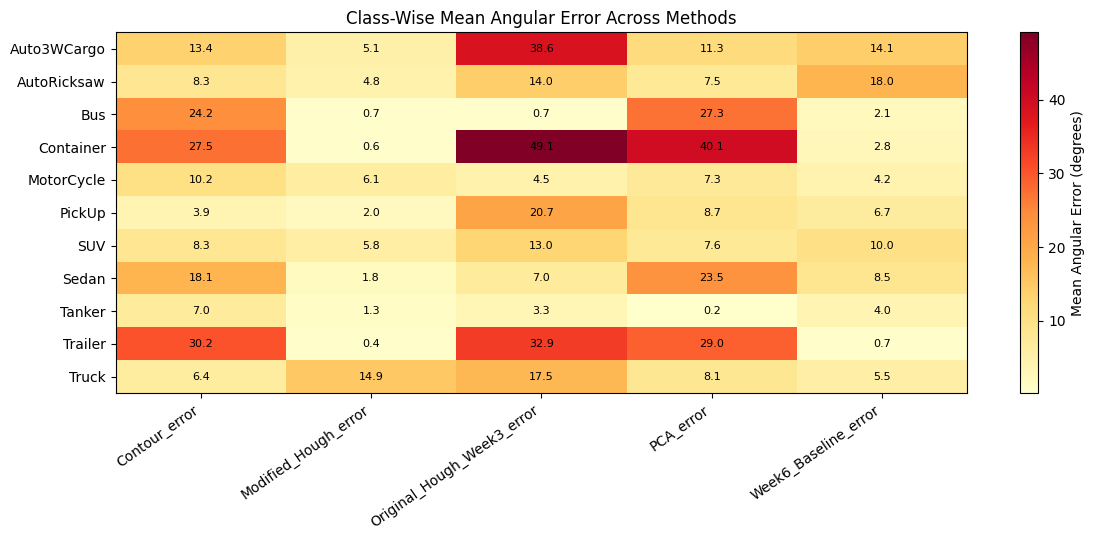

In [29]:
pivot = classwise.pivot(
    index='Vehicle_Class',
    columns='Method',
    values='Mean_Error'
)

fig, ax = plt.subplots(
    figsize=(12, max(5, len(pivot) * 0.5))
)

im = ax.imshow(
    pivot.to_numpy(),
    aspect='auto',
    cmap='YlOrRd'
)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(
    pivot.columns,
    rotation=35,
    ha='right'
)

ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):

        value = pivot.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i, f'{value:.1f}',
                ha='center',
                va='center',
                fontsize=8
            )

fig.colorbar(
    im,
    ax=ax,
    label='Mean Angular Error (degrees)'
)

ax.set_title(
    'Class-Wise Mean Angular Error Across Methods'
)

plt.tight_layout()

plt.savefig(
    FIG / '01_classwise_error_heatmap.png',
    dpi=180
)

plt.show()

## 8. Identification of Common High-Error Observations

The main objective of Week 7 is to investigate whether different orientation-estimation methods fail on the same individual vehicles.

An angular error of 30° or greater is used as the threshold for identifying a high-error prediction.

For each vehicle, the number of methods producing high errors is calculated.

The analysis distinguishes between:

1. Vehicles where only one method produces a high error.
2. Vehicles where two methods produce high errors.
3. Vehicles where three methods produce high errors.
4. Vehicles where all four methods produce high errors.

Vehicles with high errors across multiple methods are particularly important because they may reveal limitations shared by conventional image-processing approaches.

However, shared errors do not automatically prove that the methods fail for the same reason.

Visual inspection is required to determine whether factors such as vehicle geometry, background interference, unclear boundaries, or image quality contribute to these errors.

In [38]:
# WEEK 7: SHARED FAILURE ANALYSIS

ERROR_THRESHOLD = 30

CORE_METHODS = [
    'PCA_error',
    'Original_Hough_Week3_error',
    'Contour_error',
    'Modified_Hough_error'
]

# Count high-error methods for every vehicle
df['High_Method_Count'] = (
    df[CORE_METHODS] >= ERROR_THRESHOLD
).sum(axis=1)

# At least 2 methods fail
shared = df[
    df['High_Method_Count'] >= 2
].copy()

# At least 3 methods fail
three_or_more = df[
    df['High_Method_Count'] >= 3
].copy()

# All 4 methods fail
all_four = df[
    df['High_Method_Count'] == 4
].copy()

# Save tables
shared.to_csv(
    TABLE / '04_shared_failures.csv',
    index=False
)

three_or_more.to_csv(
    TABLE / '04_three_or_more_failures.csv',
    index=False
)

all_four.to_csv(
    TABLE / '04_all_four_failures.csv',
    index=False
)

print("SHARED FAILURE RESULTS")
print("-" * 40)

print("At least 2 methods:", len(shared))
print("At least 3 methods:", len(three_or_more))
print("All 4 methods:", len(all_four))

print("\nShared failure vehicles:")

display(
    shared[
        [
            'Vehicle_ID',
            'Vehicle_Class',
            'High_Method_Count'
        ] + CORE_METHODS
    ].sort_values(
        'High_Method_Count',
        ascending=False
    )
)

# Verify saved CSV
saved = pd.read_csv(
    TABLE / '04_shared_failures.csv'
)

print("\nRows in saved CSV:", len(saved))

assert len(saved) == 7, (
    "Expected 7 shared failures based on diagnostics."
)

SHARED FAILURE RESULTS
----------------------------------------
At least 2 methods: 7
At least 3 methods: 2
All 4 methods: 0

Shared failure vehicles:


,Vehicle_ID,Vehicle_Class,High_Method_Count,PCA_error,Original_Hough_Week3_error,Contour_error,Modified_Hough_error
84,cLEH_vQvJ_zAUO_vehicle_1,Trailer,3,81.71,82.39,89.00,0.792005
49,y0bo_oHBY_y2mz_vehicle_1,Container,3,34.67,77.16,34.10,0.485273
7,WB91_YzXz_82r4_vehicle_1,Container,2,42.07,NaN,42.36,0.466571
23,Kg67_1U8u_Rx2q_vehicle_1,MotorCycle,2,56.98,NaN,36.66,10.934059
8,tc9H_Ng2A_DWcC_vehicle_1,Bus,2,52.71,0.46,45.18,0.134703
34,hn8n_2cU8_01No_vehicle_1,Sedan,2,72.90,1.39,71.45,1.384801
33,dDHH_wv1m_jsew_vehicle_1,SUV,2,77.91,1.82,85.88,1.096113



Rows in saved CSV: 7


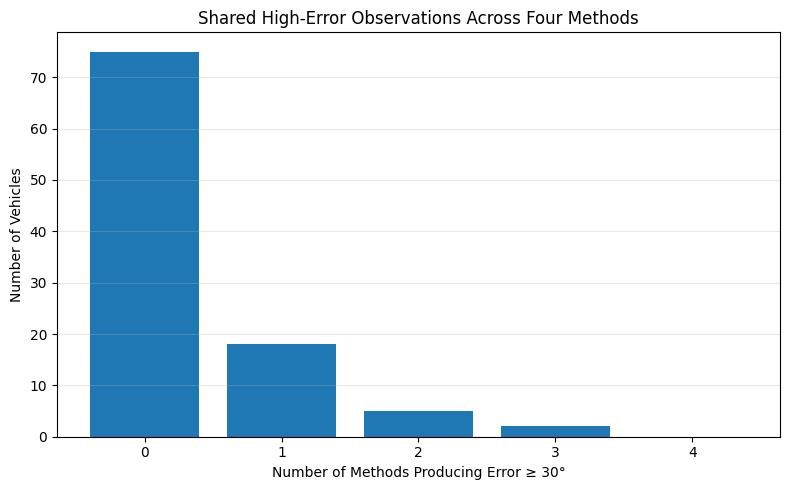

In [31]:
counts = (
    df['High_Method_Count']
    .value_counts()
    .reindex(range(5), fill_value=0)
)

plt.figure(figsize=(8, 5))

plt.bar(
    counts.index,
    counts.values
)

plt.xlabel(
    'Number of Methods Producing Error ≥ 30°'
)

plt.ylabel('Number of Vehicles')

plt.title(
    'Shared High-Error Observations Across Four Methods'
)

plt.xticks(range(5))

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIG / '02_shared_failure_counts.png',
    dpi=180
)

plt.show()

## 9. Investigation of Modified Hough Improvements and Regressions

The Modified Hough Transform was developed during Week 6 to address limitations observed in the original Hough approach.

However, filtering short line segments and selecting a dominant orientation group may not improve every vehicle prediction.

For some vehicles, these operations may remove useful lines or select an incorrect dominant direction.

To investigate this, the angular errors of Modified Hough are compared with those of the Week 6 baseline.

The difference is calculated as:

Error Difference = Modified Hough Error − Baseline Hough Error

Interpretation:

- Negative difference: Modified Hough produces a smaller angular error.
- Positive difference: Modified Hough produces a larger angular error.
- Zero difference: Both methods produce equal angular errors.

The comparison identifies vehicles with the greatest improvements and regressions.

The historical Week 3 Hough predictions are also retained for reference, but they are not treated as identical to the Week 6 baseline.

In [32]:
df['Modified_minus_Week6_Baseline'] = (
    df['Modified_Hough_error']
    - df['Week6_Baseline_error']
)

df['Modified_minus_Original_Week3'] = (
    df['Modified_Hough_error']
    - df['Original_Hough_Week3_error']
)

comparison = df[
    df['Modified_minus_Week6_Baseline'].notna()
].copy()

improved = comparison[
    comparison['Modified_minus_Week6_Baseline'] < 0
]

worsened = comparison[
    comparison['Modified_minus_Week6_Baseline'] > 0
]

unchanged = comparison[
    comparison['Modified_minus_Week6_Baseline'] == 0
]

print("Modified Hough comparison:")
print("Improved:", len(improved))
print("Worsened:", len(worsened))
print("Unchanged:", len(unchanged))

worst_regressions = comparison.sort_values(
    'Modified_minus_Week6_Baseline',
    ascending=False
)

best_improvements = comparison.sort_values(
    'Modified_minus_Week6_Baseline',
    ascending=True
)

worst_regressions.head(15).to_csv(
    TABLE / '05_modified_hough_regressions.csv',
    index=False
)

best_improvements.head(15).to_csv(
    TABLE / '06_modified_hough_improvements.csv',
    index=False
)

print("\nLargest regressions:")

display(
    worst_regressions[
        [
            'Vehicle_ID',
            'Vehicle_Class',
            'Week6_Baseline_error',
            'Modified_Hough_error',
            'Modified_minus_Week6_Baseline'
        ]
    ].head(10)
)

Modified Hough comparison:
Improved: 65
Worsened: 35
Unchanged: 0

Largest regressions:


,Vehicle_ID,Vehicle_Class,Week6_Baseline_error,Modified_Hough_error,Modified_minus_Week6_Baseline
70,lPCV_CAG5_X9at_vehicle_2,Truck,14.163995,59.823794,45.659799
69,5QtK_2GHz_wRDq_vehicle_1,SUV,6.853727,34.000151,27.146424
26,K8fi_E7BV_E33r_vehicle_1,MotorCycle,3.269941,23.672508,20.402568
0,KNyT_zacV_LpYg_vehicle_1,MotorCycle,0.486686,16.886478,16.399792
15,6TWc_P2qX_R4VI_vehicle_1,MotorCycle,0.498020,13.806670,13.308649
38,jlWW_Ztu4_0drW_vehicle_1,AutoRicksaw,4.153422,15.841284,11.687862
29,sEEm_KbEu_D5wV_vehicle_1,MotorCycle,7.435989,13.393261,5.957271
48,qWs1_rR7s_qewk_vehicle_1,MotorCycle,11.618762,17.193776,5.575013
95,mCA9_HWns_Z2vx_vehicle_1,MotorCycle,3.548350,8.689927,5.141577
59,SR9o_F2yn_nN3o_vehicle_1,MotorCycle,1.626188,6.212798,4.586610


## 10. Visual Investigation of High-Error Vehicles

Numerical comparisons indicate which vehicles produce large errors, but they cannot establish the physical reasons for those errors.

Therefore, selected vehicle crops are visually examined.

The investigation focuses on:

1. Vehicles with the largest Modified Hough errors.
2. Vehicles where Modified Hough performs worse than the Week 6 baseline.
3. Vehicles where all four orientation-estimation methods produce high errors.

For each selected vehicle, the following are displayed:

- Original vehicle crop.
- Canny edge map.
- All detected Hough line segments.
- Line segments selected by Modified Hough.

These visualizations help investigate whether the detected lines correspond to the vehicle's longitudinal direction.

Potential limitations include:

- Background edges interfering with line detection.
- Strong edges perpendicular to the vehicle's main axis.
- Weak or fragmented vehicle boundaries.
- Vehicle geometry producing ambiguous line directions.
- Short-line filtering removing useful segments.
- Dominant orientation grouping selecting an incorrect direction.

These are possible explanations, not automatically confirmed causes.

The actual observations must be recorded after inspecting the images.

In [33]:
worst_modified_ids = (
    df.sort_values(
        'Modified_Hough_error',
        ascending=False
    )['Vehicle_ID']
    .head(10)
    .tolist()
)

regression_ids = (
    df.sort_values(
        'Modified_minus_Week6_Baseline',
        ascending=False
    )['Vehicle_ID']
    .head(10)
    .tolist()
)

shared_ids = (
    shared['Vehicle_ID']
    .head(10)
    .tolist()
)

case_ids = list(
    dict.fromkeys(
        worst_modified_ids
        + regression_ids
        + shared_ids
    )
)

print("Selected vehicles for visual investigation:")
print(len(case_ids))

display(
    df[
        df['Vehicle_ID'].isin(case_ids)
    ][
        [
            'Vehicle_ID',
            'Vehicle_Class',
            'Crop_Available',
            'High_Method_Count'
        ]
    ]
)

Selected vehicles for visual investigation:
19


,Vehicle_ID,Vehicle_Class,Crop_Available,High_Method_Count
0,KNyT_zacV_LpYg_vehicle_1,MotorCycle,True,0
7,WB91_YzXz_82r4_vehicle_1,Container,True,2
8,tc9H_Ng2A_DWcC_vehicle_1,Bus,True,2
15,6TWc_P2qX_R4VI_vehicle_1,MotorCycle,True,0
17,nnOQ_5C6s_y5jd_vehicle_1,SUV,True,1
23,Kg67_1U8u_Rx2q_vehicle_1,MotorCycle,True,2
26,K8fi_E7BV_E33r_vehicle_1,MotorCycle,True,0
29,sEEm_KbEu_D5wV_vehicle_1,MotorCycle,True,0
33,dDHH_wv1m_jsew_vehicle_1,SUV,True,2
34,hn8n_2cU8_01No_vehicle_1,Sedan,True,2


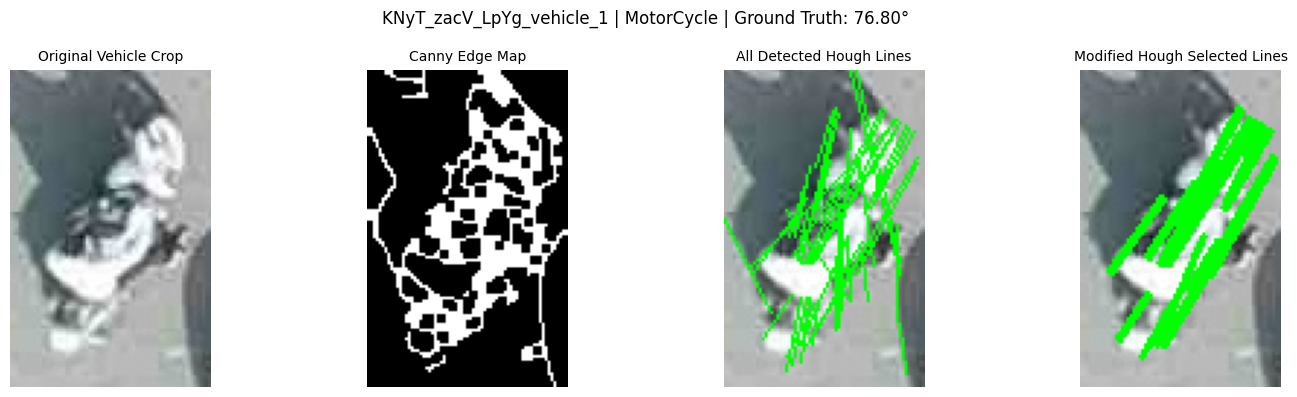

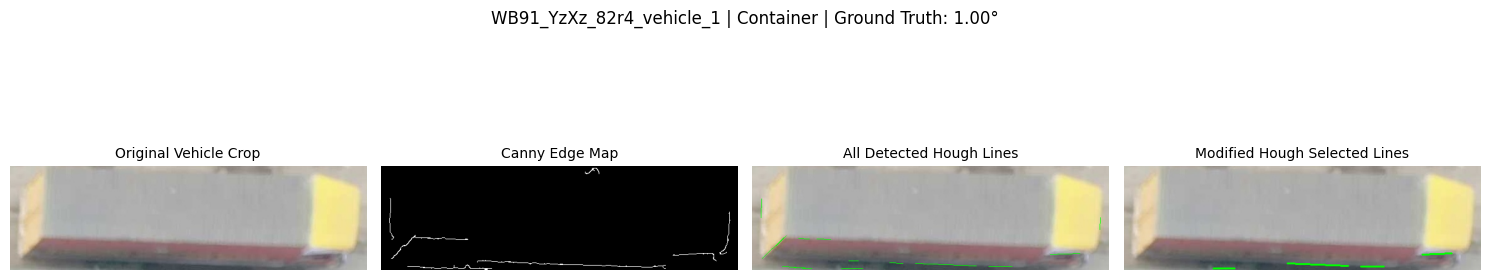

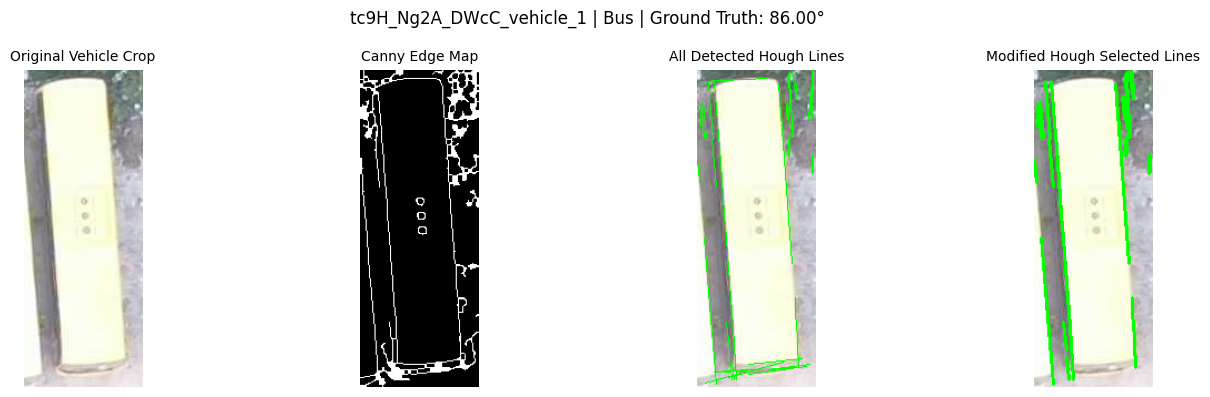

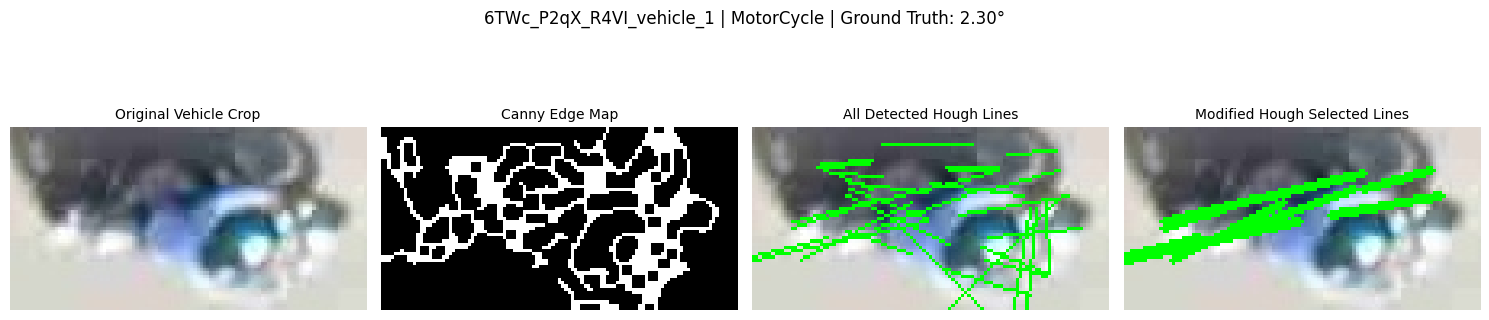

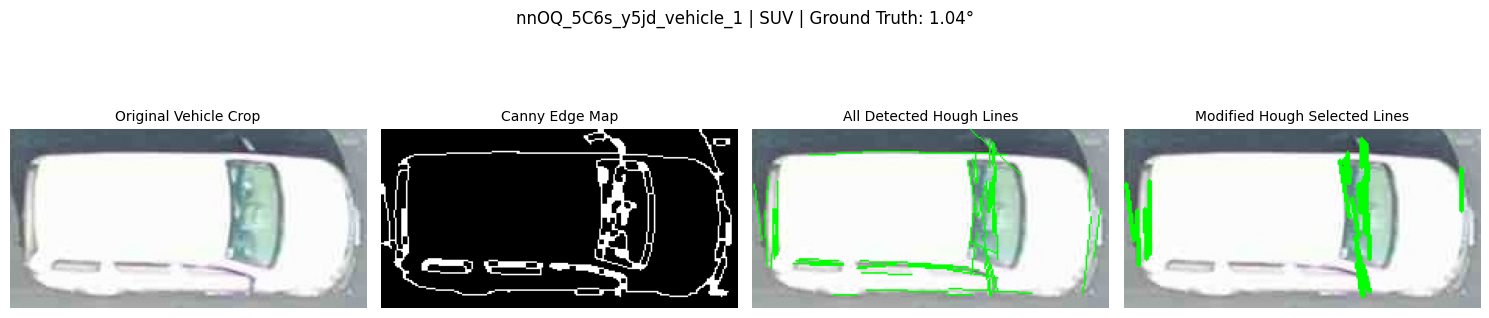

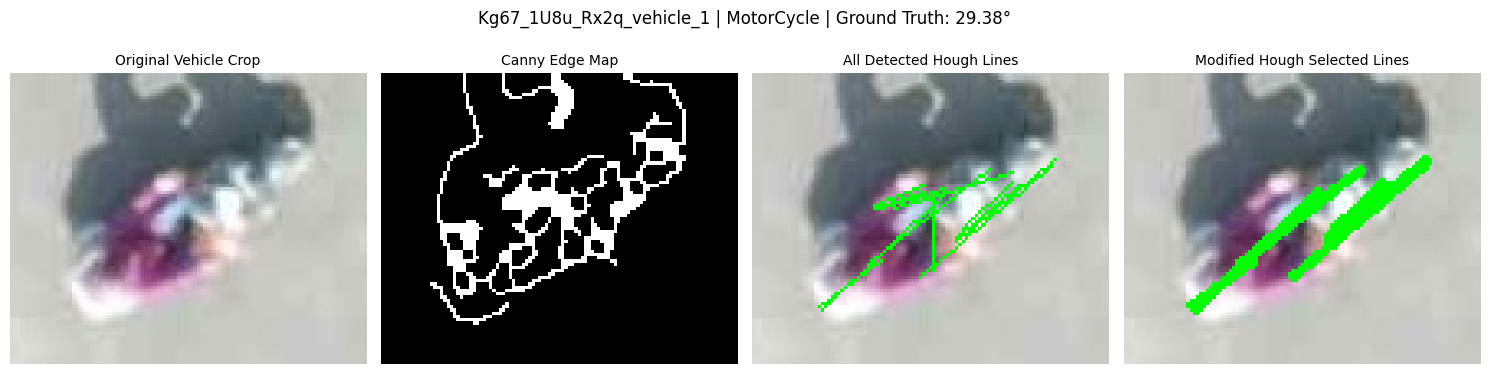

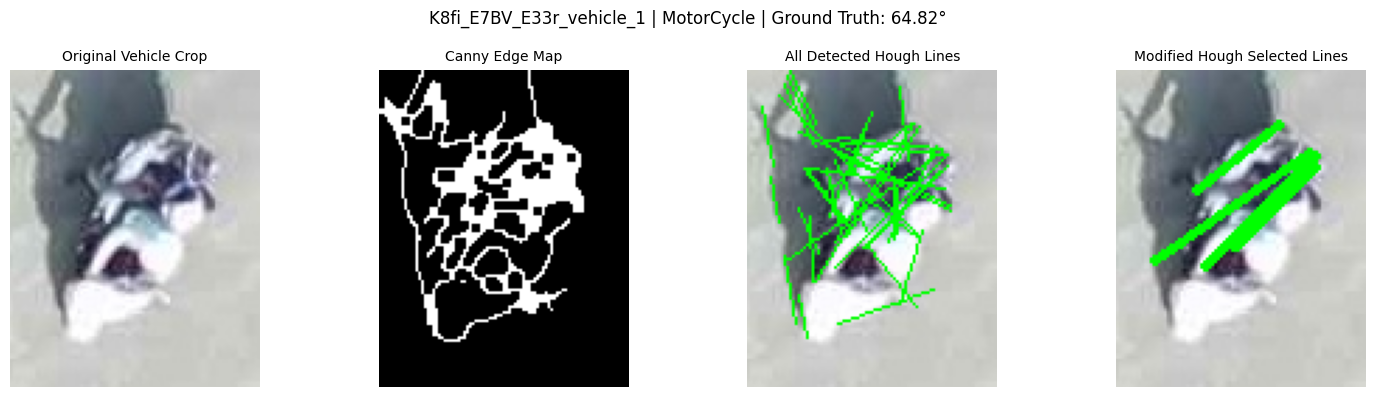

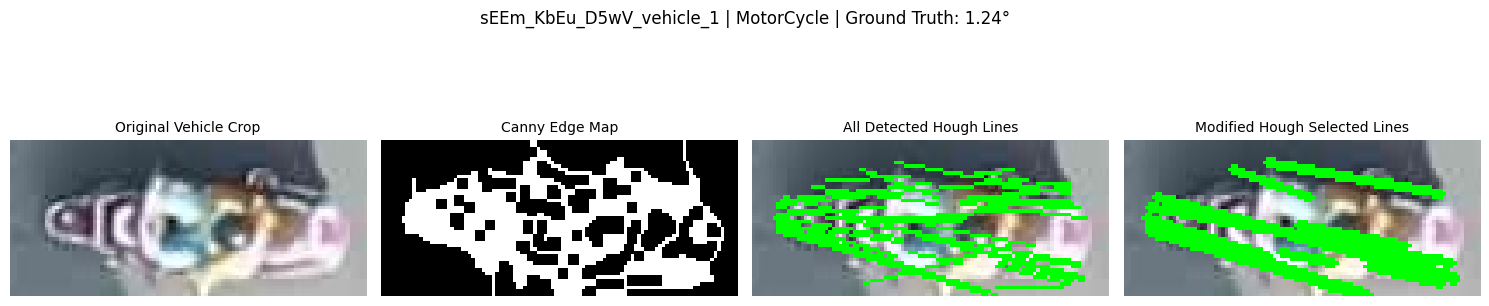

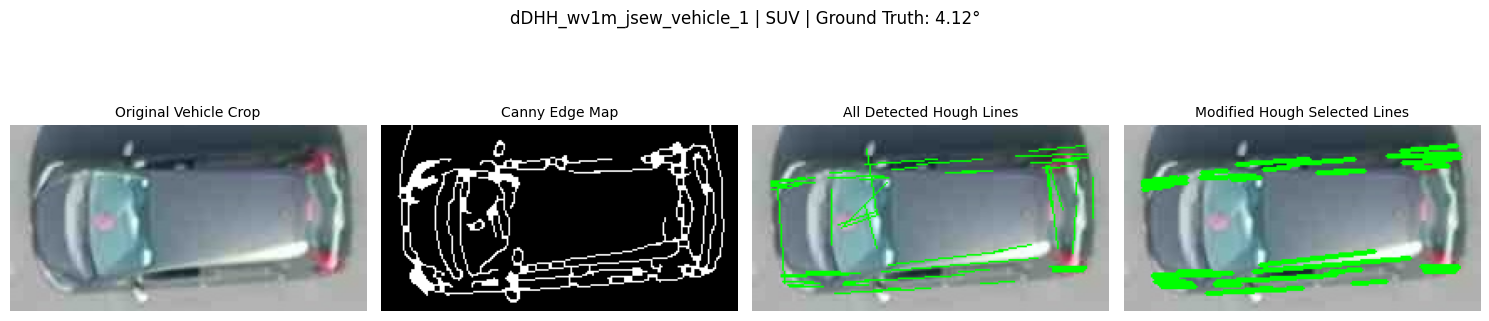

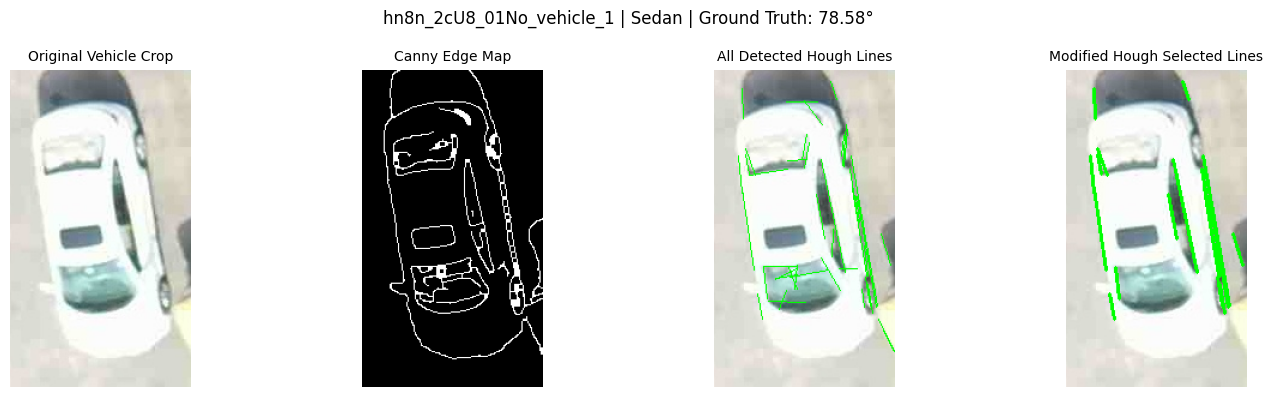

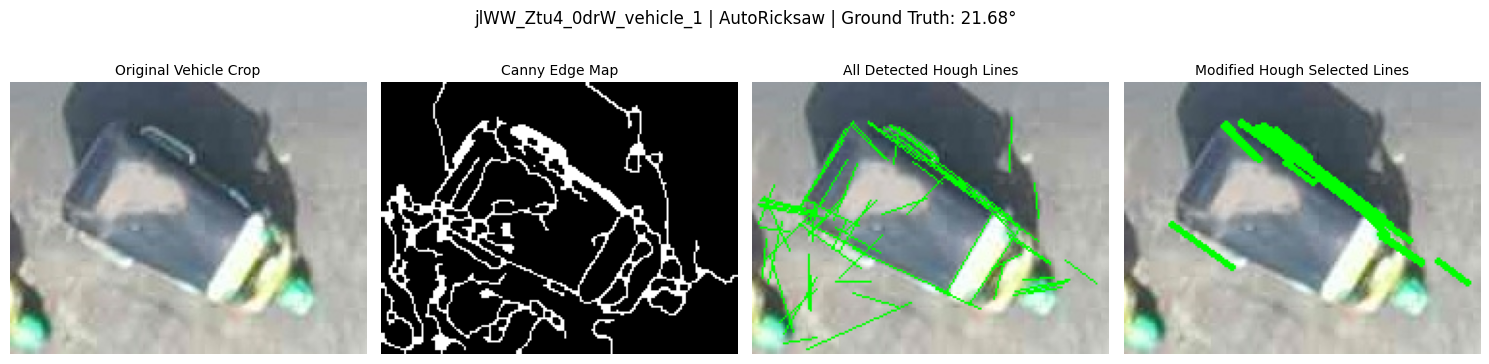

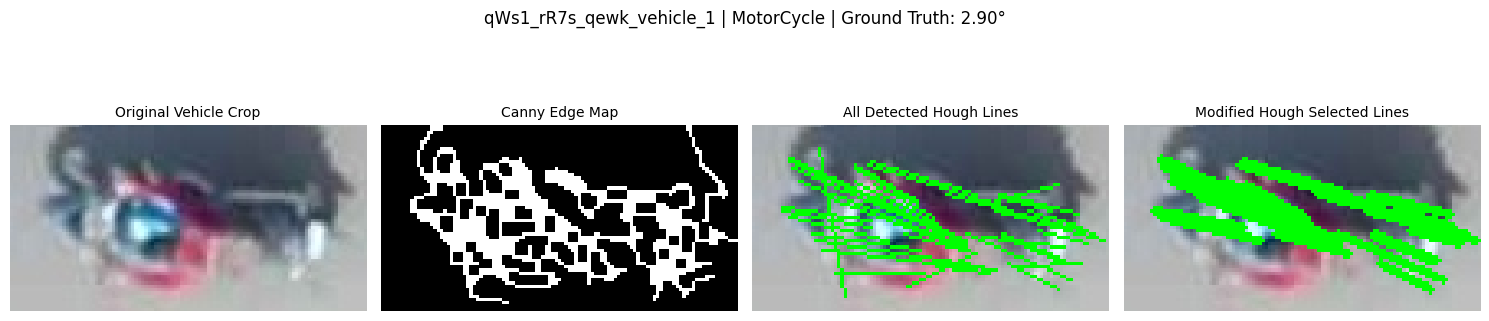

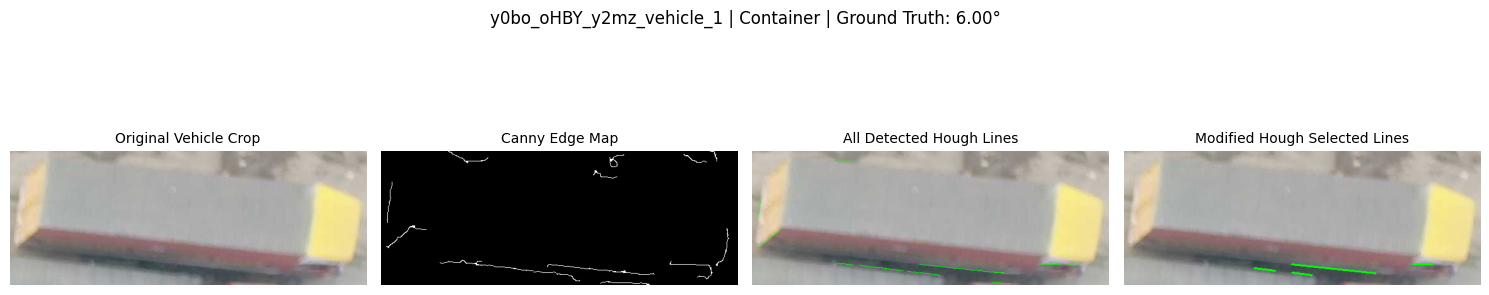

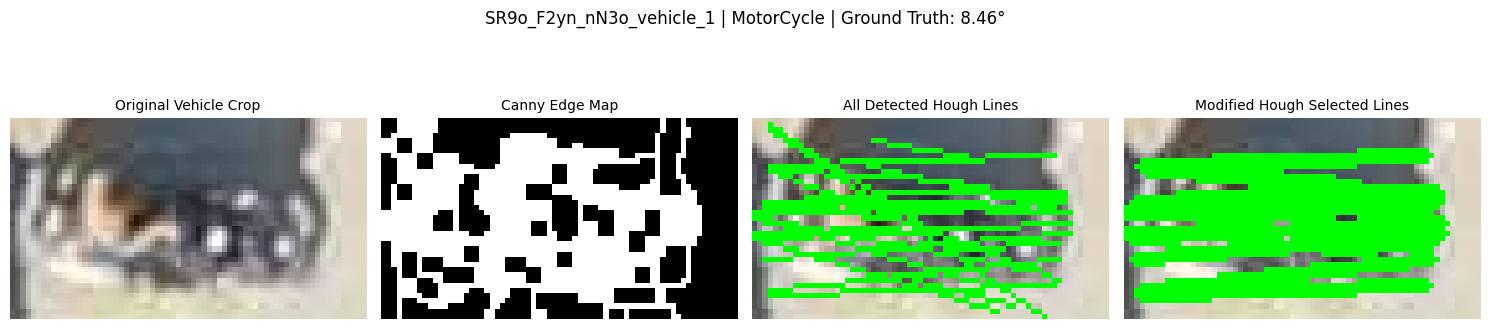

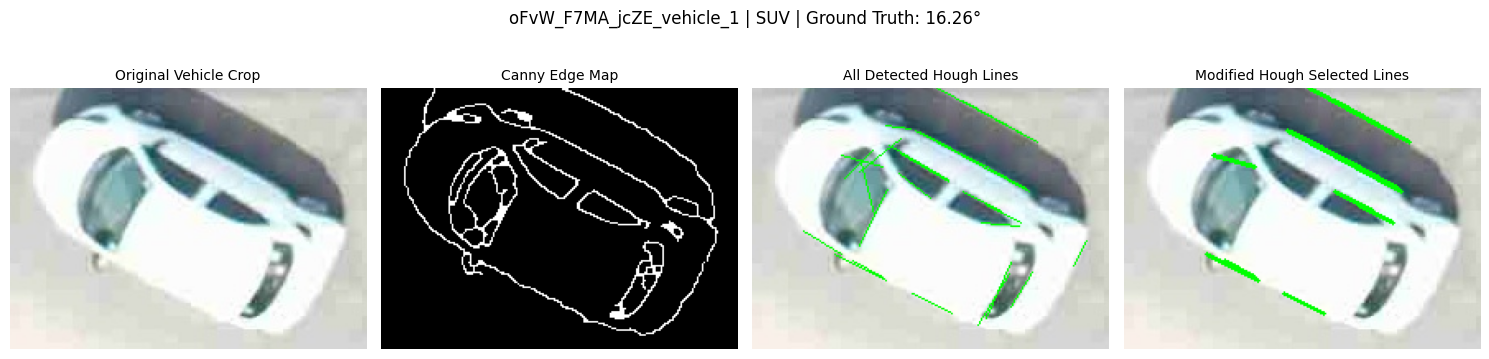

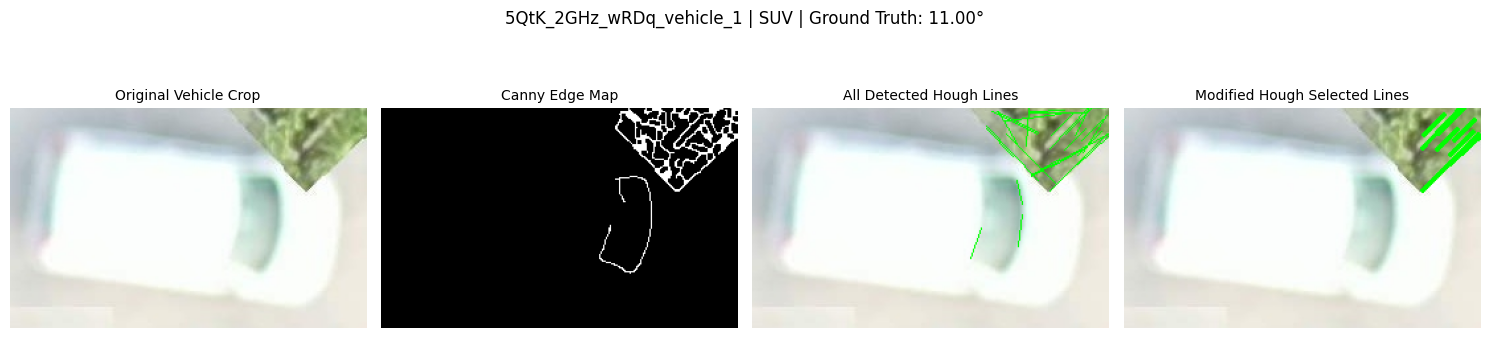

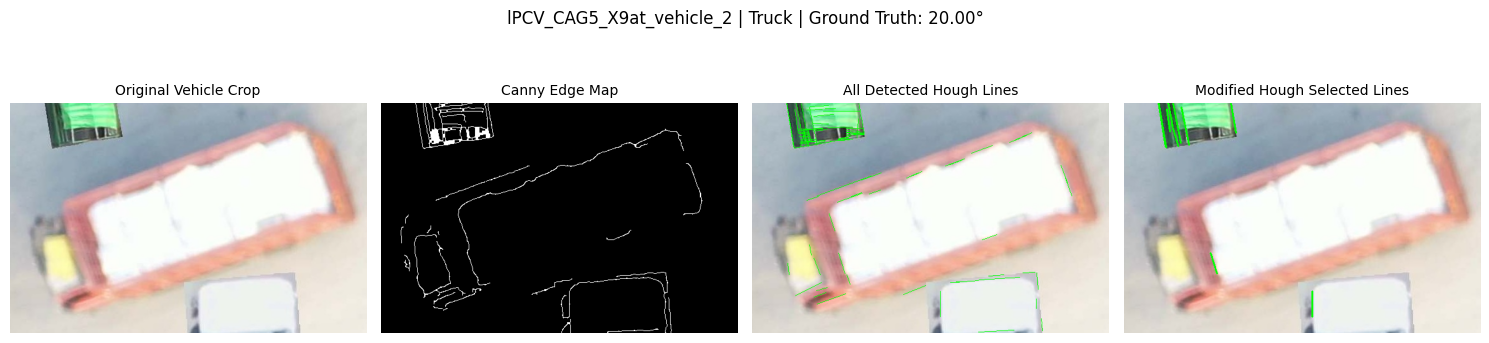

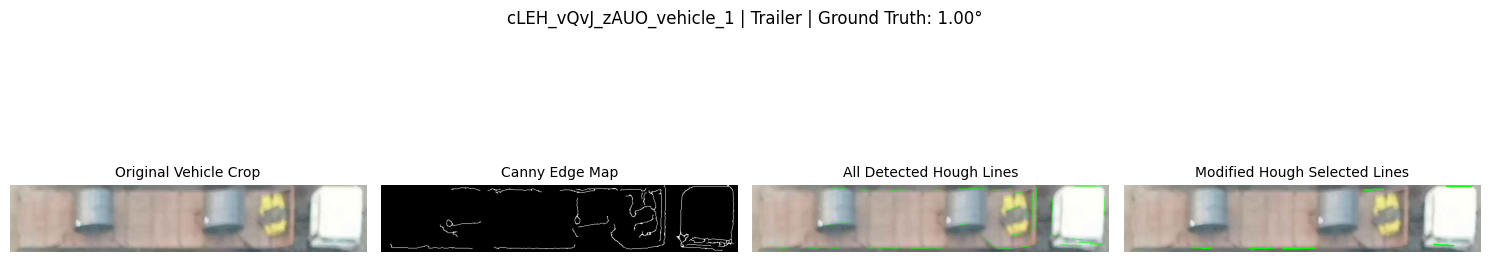

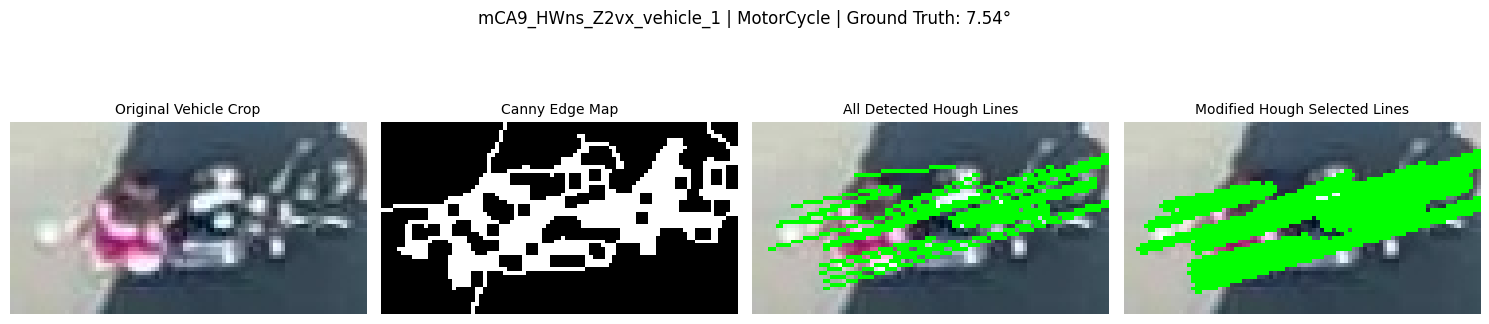

In [34]:
def show_case(row):

    image = cv2.imread(row.Crop_Path)

    if image is None:
        return

    (
        orientation,
        axis,
        all_lines,
        selected_lines,
        edges
    ) = modified_hough(
        image,
        **BEST_PARAMS
    )

    all_overlay = image.copy()
    selected_overlay = image.copy()

    for x1, y1, x2, y2 in all_lines:

        cv2.line(
            all_overlay,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            1
        )

    for x1, y1, x2, y2 in selected_lines:

        cv2.line(
            selected_overlay,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

    images = [
        image,
        edges,
        all_overlay,
        selected_overlay
    ]

    titles = [
        'Original Vehicle Crop',
        'Canny Edge Map',
        'All Detected Hough Lines',
        'Modified Hough Selected Lines'
    ]

    fig, axes = plt.subplots(
        1, 4,
        figsize=(15, 4)
    )

    for ax, img, title in zip(
        axes,
        images,
        titles
    ):

        if img.ndim == 2:

            ax.imshow(
                img,
                cmap='gray'
            )

        else:

            ax.imshow(
                cv2.cvtColor(
                    img,
                    cv2.COLOR_BGR2RGB
                )
            )

        ax.set_title(
            title,
            fontsize=10
        )

        ax.axis('off')

    fig.suptitle(
        f"{row.Vehicle_ID} | "
        f"{row.Vehicle_Class} | "
        f"Ground Truth: {getattr(row, GT):.2f}°"
    )

    plt.tight_layout()

    plt.savefig(
        VIS / f'{row.Vehicle_ID}.png',
        dpi=160,
        bbox_inches='tight'
    )

    plt.show()
    plt.close(fig)


selected_cases = df[
    df['Vehicle_ID'].isin(case_ids)
    & df['Crop_Available']
]

for row in selected_cases.itertuples(index=False):

    show_case(row)

## 11. Documentation of Observed Failure Reasons

The visual investigation is used to document the possible causes of inaccurate orientation estimation.

Each selected observation is reviewed individually.

The analysis considers whether the errors arise from:

1. Vehicle geometry or shape ambiguity.
2. Background interference.
3. Weak or fragmented edges.
4. Incorrect dominant line selection.
5. Removal of useful lines during filtering.
6. Poor image quality or limited resolution.
7. Other visually observable limitations.

The recorded reasons are based on the available visual evidence.

When the cause cannot be determined confidently, the observation is marked as uncertain.

The purpose is to distinguish limitations shared by multiple orientation-estimation methods from limitations specific to Modified Hough.

Since PCA and Contour predictions are reused from Week 3, their numerical errors can be compared directly. However, Hough line visualizations alone cannot confirm the specific internal failure mechanism of PCA or Contour.

In [35]:
review = df[
    df['Vehicle_ID'].isin(case_ids)
][
    [
        'Vehicle_ID',
        'Vehicle_Class',
        'Crop_Available',
        'Ground_Truth_Orientation_deg',
        'PCA_error',
        'Original_Hough_Week3_error',
        'Contour_error',
        'Modified_Hough_error',
        'High_Method_Count'
    ]
].copy()

review['Observed_Failure_Reason'] = ''
review['Visual_Evidence'] = ''
review['Methods_Affected'] = ''
review['Confidence'] = ''
review['Additional_Notes'] = ''

review.to_csv(
    TABLE / '07_manual_failure_analysis.csv',
    index=False
)

print("Manual failure-analysis table created.")

display(review.head())

Manual failure-analysis table created.


,Vehicle_ID,Vehicle_Class,Crop_Available,Ground_Truth_Orientation_deg,PCA_error,Original_Hough_Week3_error,Contour_error,Modified_Hough_error,High_Method_Count,Observed_Failure_Reason,Visual_Evidence,Methods_Affected,Confidence,Additional_Notes
0,KNyT_zacV_LpYg_vehicle_1,MotorCycle,True,76.80,4.29,5.64,9.51,16.886478,0,,,,,
7,WB91_YzXz_82r4_vehicle_1,Container,True,1.00,42.07,NaN,42.36,0.466571,2,,,,,
8,tc9H_Ng2A_DWcC_vehicle_1,Bus,True,86.00,52.71,0.46,45.18,0.134703,2,,,,,
15,6TWc_P2qX_R4VI_vehicle_1,MotorCycle,True,2.30,2.38,2.60,2.30,13.806670,0,,,,,
17,nnOQ_5C6s_y5jd_vehicle_1,SUV,True,1.04,1.72,13.65,1.04,84.941047,1,,,,,


## 12. Discussion and Conclusions

Week 7 investigates the limitations of the previously implemented vehicle orientation-estimation methods using the original 100 vehicle observations.

The study compares PCA, Original Hough Transform, Modified Hough Transform, and Contour-Based estimation.

The analysis includes overall angular errors, vehicle-class-wise performance, and the identification of observations where multiple methods produce high errors.

The Modified Hough Transform is also compared with the Week 6 baseline to determine where the existing modifications improve or worsen orientation estimates.

Selected difficult observations are examined visually using the original vehicle crops, edge maps, and detected Hough line segments.

The findings will help distinguish common difficulties associated with vehicle appearance and image quality from limitations specific to individual algorithms.

The conclusions regarding failure causes will be finalized after reviewing the generated visualizations and completing the manual failure-analysis table.

### Next Stage

Week 8 will investigate front–rear identification as a separate stage of vehicle heading estimation.

The findings from Week 7 will provide information about the reliability and limitations of the existing orientation-estimation methods before further development.

In [39]:
df.to_csv(
    TABLE / '08_final_100_vehicle_results.csv',
    index=False
)

summary_text = f"""
ECE501 — WEEK 7 ANALYSIS SUMMARY

Project:
Vehicle Orientation Estimation Using Conventional Image Processing

Dataset:
Original 100 vehicle observations.

Total observations: {len(df)}

Available crops: {df['Crop_Available'].sum()}

Unavailable crops: {(~df['Crop_Available']).sum()}

Methods:
1. PCA
2. Original Hough Transform (Week 3)
3. Contour-Based Estimation
4. Modified Hough Transform (Week 6)

Additional reference:
Week 6 Hough baseline

High-error threshold:
30 degrees

Vehicles with high errors in at least two methods:
{len(shared)}

Vehicles with high errors in all four methods:
{len(shared)}

Vehicles with high errors in at least three methods:
{(df['High_Method_Count'] >= 3).sum()}

Modified Hough comparison against Week 6 baseline:

Improved: {len(improved)}
Worsened: {len(worsened)}
Unchanged: {len(unchanged)}

Important Notes:

- The same 100 vehicle identifiers were retained.
- No additional vehicles were introduced.
- No new estimation methods were introduced.
- No new parameter tuning was performed.
- Historical PCA, Hough, and Contour predictions were reused.
- Modified Hough was evaluated using the Week 6 implementation.
- Specific failure causes require manual visual verification.

Week 8:
Front–rear identification.
"""

summary_path = OUT / 'Week7_Analysis_Summary.txt'

summary_path.write_text(summary_text)

print(summary_text)

print("\nAll results saved to:")
print(OUT)


ECE501 — WEEK 7 ANALYSIS SUMMARY

Project:
Vehicle Orientation Estimation Using Conventional Image Processing

Dataset:
Original 100 vehicle observations.

Total observations: 100

Available crops: 100

Unavailable crops: 0

Methods:
1. PCA
2. Original Hough Transform (Week 3)
3. Contour-Based Estimation
4. Modified Hough Transform (Week 6)

Additional reference:
Week 6 Hough baseline

High-error threshold:
30 degrees

Vehicles with high errors in at least two methods:
7

Vehicles with high errors in all four methods:
7

Vehicles with high errors in at least three methods:
2

Modified Hough comparison against Week 6 baseline:

Improved: 65
Worsened: 35
Unchanged: 0

Important Notes:

- The same 100 vehicle identifiers were retained.
- No additional vehicles were introduced.
- No new estimation methods were introduced.
- No new parameter tuning was performed.
- Historical PCA, Hough, and Contour predictions were reused.
- Modified Hough was evaluated using the Week 6 implementation.
- 